# Student Performance Machine Learning

This notebook begins a reproducible regression workflow for predicting final Mathematics grades using the UCI Student Performance dataset. The target is `G3`. The previous-period grades `G1` and `G2` are excluded from the predictors by design.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

## 2. Load the dataset

In [2]:
# The UCI file is semicolon-delimited.
data_path = '../data/student-mat.csv'
student_data = pd.read_csv(data_path, sep=';')

display(student_data.head())
print(f'Dataset shape: {student_data.shape}')
print('Column names:')
print(student_data.columns.tolist())
print('Data types:')
display(student_data.dtypes.to_frame('data_type'))
print('Missing values by column:')
display(student_data.isna().sum().to_frame('missing_values'))
print(f'Duplicate rows: {student_data.duplicated().sum()}')

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


Dataset shape: (395, 33)
Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
Data types:


,data_type
school,object
sex,object
age,int64
address,object
famsize,object
Pstatus,object
Medu,int64
Fedu,int64
Mjob,object
Fjob,object


Missing values by column:


,missing_values
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Duplicate rows: 0


## 3. Understand the data

In [3]:
target_column = 'G3'
excluded_columns = ['G1', 'G2']

target = student_data[target_column]
predictors = student_data.drop(columns=[target_column] + excluded_columns)

print(f'Target: {target_column}')
print(f'Predictor shape after excluding G1 and G2: {predictors.shape}')
print(f'Excluded columns: {excluded_columns}')
assert target_column not in predictors.columns
assert all(column not in predictors.columns for column in excluded_columns)
print('Confirmed: G3 is the target, and G1 and G2 are excluded from predictors.')

print('Descriptive statistics for the full dataset:')
display(student_data.describe(include='all').transpose())

numerical_columns = student_data.select_dtypes(include=['number']).columns.tolist()
categorical_columns = student_data.select_dtypes(exclude=['number']).columns.tolist()

print(f'Numerical variables ({len(numerical_columns)}):')
print(numerical_columns)
print(f'Categorical variables ({len(categorical_columns)}):')
print(categorical_columns)

Target: G3
Predictor shape after excluding G1 and G2: (395, 30)
Excluded columns: ['G1', 'G2']
Confirmed: G3 is the target, and G1 and G2 are excluded from predictors.
Descriptive statistics for the full dataset:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Numerical variables (16):
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']
Categorical variables (17):
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


## 4. Data-quality checks

The following checks look for invalid ranges and potential outliers using the interquartile range (IQR) rule. These observations are reported for review; no rows are removed at this audit stage.

In [4]:
def iqr_outlier_count(series):
    first_quartile = series.quantile(0.25)
    third_quartile = series.quantile(0.75)
    iqr = third_quartile - first_quartile
    lower_fence = first_quartile - 1.5 * iqr
    upper_fence = third_quartile + 1.5 * iqr
    outlier_count = ((series < lower_fence) | (series > upper_fence)).sum()
    return lower_fence, upper_fence, int(outlier_count)

print(f"Absences range: {student_data['absences'].min()} to {student_data['absences'].max()}")
print(f"G3 range: {student_data['G3'].min()} to {student_data['G3'].max()}")
print(f"G3 values outside 0 to 20: {((student_data['G3'] < 0) | (student_data['G3'] > 20)).sum()}")
print(f"Absence values below zero: {(student_data['absences'] < 0).sum()}")

for column in ['absences', 'G3']:
    lower_fence, upper_fence, outlier_count = iqr_outlier_count(student_data[column])
    print(
        f'{column} IQR fences: {lower_fence:.1f} to {upper_fence:.1f}; '
        f'potential outliers: {outlier_count}'
    )

Absences range: 0 to 75
G3 range: 0 to 20
G3 values outside 0 to 20: 0
Absence values below zero: 0
absences IQR fences: -12.0 to 20.0; potential outliers: 15
G3 IQR fences: -1.0 to 23.0; potential outliers: 0


## 5. Data-audit findings

The file contains 395 student records and 33 columns. It has no missing values and no duplicate rows. There are 16 numerical variables and 17 categorical variables. The final grade `G3` ranges from 0 to 20, so no final grades are outside the documented scale. The IQR check identifies 15 potential high-absence observations above its upper fence of 20 absences; these are flagged for awareness rather than removed. `G3` has no IQR-flagged outliers. The target is `G3`, while `G1` and `G2` are excluded from the predictor set because they are previous-period grades.

## 6. Initial data visualisation

The target distribution is inspected before modelling.

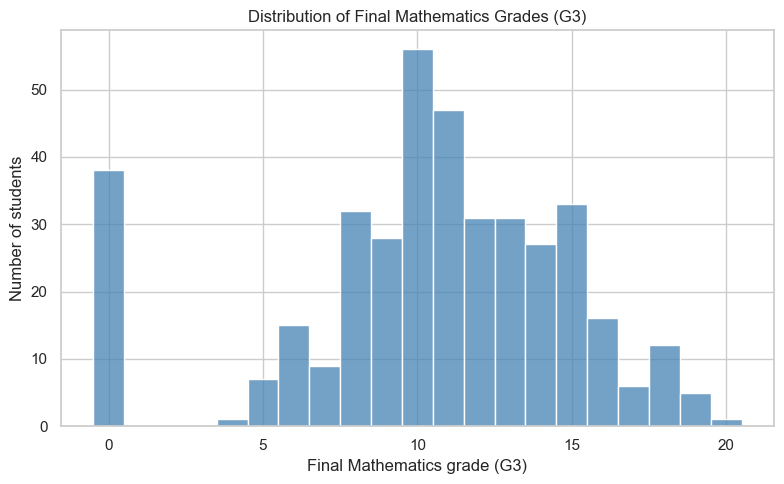

In [5]:
plt.figure(figsize=(8, 5))
sns.histplot(target, bins=21, discrete=True, color='steelblue')
plt.title('Distribution of Final Mathematics Grades (G3)')
plt.xlabel('Final Mathematics grade (G3)')
plt.ylabel('Number of students')
plt.tight_layout()
plt.show()

## 7. Train/test split and preprocessing

The target is `G3`, while `G1` and `G2` remain excluded because they are previous-period grades. The predictors are split into numerical and categorical variables. An 80/20 train/test split is used with `random_state=42` so the evaluation is reproducible.

Numerical predictors are standardised with `StandardScaler`, while categorical predictors are one-hot encoded with `OneHotEncoder(handle_unknown='ignore')`. A `ColumnTransformer` applies the appropriate transformation to each type of predictor, and a scikit-learn `Pipeline` keeps these steps together for later model training.

The pipeline is fitted using the training data only. The untouched test data is transformed afterwards and is reserved for final evaluation, which prevents information from the test set influencing preprocessing.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    predictors,
    target,
    test_size=0.2,
    random_state=RANDOM_STATE
)

numerical_predictors = X_train.select_dtypes(include=['number']).columns.tolist()
categorical_predictors = X_train.select_dtypes(exclude=['number']).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', StandardScaler(), numerical_predictors),
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_predictors)
    ]
)

preprocessing_pipeline = Pipeline(
    steps=[('preprocessor', preprocessor)]
)

# Fit preprocessing on the training data only, then transform both splits.
X_train_prepared = preprocessing_pipeline.fit_transform(X_train, y_train)
X_test_prepared = preprocessing_pipeline.transform(X_test)

print(f'Training set: {X_train.shape[0]} rows')
print(f'Test set: {X_test.shape[0]} rows')
print(f'Numerical predictors ({len(numerical_predictors)}): {numerical_predictors}')
print(f'Categorical predictors ({len(categorical_predictors)}): {categorical_predictors}')
print(f'Prepared training shape: {X_train_prepared.shape}')
print(f'Prepared test shape: {X_test_prepared.shape}')

assert len(X_train) == 316
assert len(X_test) == 79
assert X_train_prepared.shape[1] == X_test_prepared.shape[1]